# What is this car worth? Used-vehicle price prediction for Sri Lanka

**ML Lecture 7, Part 2: Final Assignment**

| | |
|---|---|
| **Problem** | Regression: predict the asking price (in lakhs, 1 lakh = Rs 100,000) of a used car listed for sale in Sri Lanka from its make, model, age, engine, transmission, fuel, town and equipment. |
| **Why it matters locally** | From 2020 to 31 January 2025 Sri Lanka suspended private vehicle imports to protect foreign reserves. With no new supply, used-car prices rose far above their international value, and buyers had no reliable way to judge whether an asking price was fair. Local studies describe buyers being exploited by unrealistic dealer prices (Jayadeera & Jayamanne, 2019; Basnayaka, 2023). The ban was lifted on 1 February 2025 (Gazette 2421/44), and this dataset was collected from 3 Dec 2024 to 5 Feb 2025, ending five days after that date. |
| **Users** | A buyer checking an asking price, a seller pricing a listing, or a leasing company valuing collateral. |
| **Data** | 9,788 listings from ikman.lk and Riyasewana.com, Dec 2024 – Feb 2025 ([Kaggle, Prasad Nirmal, v3, MIT licence](https://www.kaggle.com/datasets/prasadnirmal/srilankan-second-vehiclecar-price-dataset)). |

**How the notebook maps to the assignment brief**

| Brief requirement | Section |
|---|---|
| 1 Local problem & dataset | Above and §0 |
| 2 Proper data analysis before choosing models | §1 |
| 3 Model selection (beyond RF/XGBoost) | §2 |
| 4 Compare with existing approaches | §3 (same-data baselines) and §4 (published work) |
| 5 Justify the choice | §5 |
| 6 Interpret the output | §6 and §7 |
| 7 Front end | `app.py` (see README) |

In [1]:
import json, time, warnings

import joblib
import shap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.model_selection import cross_val_predict
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
import lightgbm as lgb
from catboost import CatBoostRegressor, Pool

from vehicle_model import (load_raw, add_features, MarketComparable, LGBModel, StackedModel, PriceModel, explain,
                           CATEGORICAL, NUMERIC, FEATURES, INPUT_COLUMNS, REFERENCE_YEAR)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*eval_set.*")
SEED = 42
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
metrics = {}   # everything quoted in REPORT.md is written here

## 0 · Load the data
The CSV is the Kaggle file unchanged (SHA-256 `4208d267…1ab`). Only the column names are tidied.

In [2]:
raw = load_raw("data/vehicle_prices.csv")
print(raw.shape)
raw.head()

(9788, 16)


,brand,model,yom,engine_cc,gear,fuel,mileage_km,town,date,leasing,condition,air_condition,power_steering,power_mirror,power_window,price
0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


## 1 · Data analysis (before choosing any model)

### 1.1 Data quality: nulls, duplicates, reposts, implausible values

In [3]:
q = {}
q["rows"] = len(raw)
q["nulls"] = int(raw.isna().sum().sum())
q["exact_duplicates"] = int(raw.duplicated().sum())

# The same car re-posted (same make, model, year, engine, mileage, town and equipment) at another
# date or price. These are not independent samples.
car_cols = INPUT_COLUMNS + ["mileage_km"]
dedup = raw.drop_duplicates().copy()
dedup["car_id"] = dedup[car_cols].astype(str).agg("|".join, axis=1)
grp = dedup.groupby("car_id").size()
q["rows_in_repost_groups"] = int(grp[grp > 1].sum())
q["repost_groups"] = int((grp > 1).sum())

q["date_min"], q["date_max"] = dedup["date"].min(), dedup["date"].max()
# Is mileage real? Compare it with 11,000 km per year of age
q["mileage_equals_11000_x_age_share"] = float((dedup.mileage_km == 11_000 * (REFERENCE_YEAR - dedup.yom)).mean())
q["engine_cc_lt_600"] = int((dedup.engine_cc < 600).sum())
q["yom_lt_1990"] = int((dedup.yom < 1990).sum())
q["condition_new"] = int((dedup.condition == "NEW").sum())
q["electric_rows"] = int((dedup.fuel == "Electric").sum())
q["electric_engine_cc_values"] = sorted(dedup.loc[dedup.fuel == "Electric", "engine_cc"].unique().tolist())[:8]
metrics["quality"] = q
pd.Series(q, dtype=object)

rows                                                                             9788
nulls                                                                               0
exact_duplicates                                                                   18
rows_in_repost_groups                                                            1471
repost_groups                                                                     613
date_min                                                                   2024-12-03
date_max                                                                   2025-02-05
mileage_equals_11000_x_age_share                                                  1.0
engine_cc_lt_600                                                                    1
yom_lt_1990                                                                       764
condition_new                                                                      94
electric_rows                                         

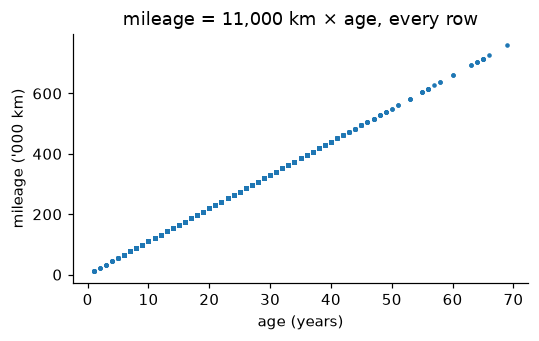

,brand,model,yom,engine_cc,fuel,price
55,AUDI,Q4,2024,1500.0,Electric,475.00
159,BYD,SEAL,2024,1500.0,Electric,394.50
242,CITROEN,E-C4,2024,1500.0,Electric,228.50
863,HONDA,FIT GP5 S GRADE,2014,1500.0,Electric,87.90
1055,HONDA,INSIGHT ZE2,2010,1330.0,Electric,76.90
1306,HYUNDAI,ZIP PLUS,2003,1100.0,Electric,21.00
1812,MG,4 TROPHY,2023,1500.0,Electric,185.00
2358,MITSUBISHI,MITSUBISHI,2013,800.0,Electric,41.45


In [4]:
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.scatter(REFERENCE_YEAR - dedup.yom, dedup.mileage_km / 1000, s=4)
ax.set(xlabel="age (years)", ylabel="mileage ('000 km)", title="mileage = 11,000 km × age, every row")
plt.tight_layout(); plt.savefig(FIG / "mileage_is_synthetic.png"); plt.show()
dedup.loc[(dedup.engine_cc < 600) | (dedup.fuel == "Electric"), ["brand", "model", "yom", "engine_cc", "fuel", "price"]].head(8)

**What the quality checks found, and what was done about each**

* **No nulls** anywhere, so no imputation is needed for the data itself. The front end still validates its inputs.
* **18 exact duplicate rows** were removed (9,788 → 9,770).
* **Reposts:** 613 groups of listings have identical attributes (1,471 rows). Most are the same car listed again on another date, though a few may be distinct cars with the same specification in the same town. A random split would put one copy in training and another in test, so the model would be marked on cars it has already seen. **Decision:** split by these groups (`GroupShuffleSplit` / `GroupKFold` on `car_id`). Grouping identical specs is conservative: it can only make the test harder.
* **Mileage is not real data.** For **100 %** of rows, mileage is exactly 11,000 km × age (plot above). The dataset author evidently filled it in from the year of manufacture. It therefore carries *no information beyond age*, and any "mileage importance" reported on this dataset is age importance counted twice. **Decision:** mileage is dropped from the model and from the front end. A real odometer reading is listed as the most valuable missing feature (§8).
* **Electric cars have made-up engine sizes** (e.g. a Tesla Model 3 at 573 cc). There are only 69 rows, and `fuel = Electric` identifies them, so `engine_cc` is kept, and EV results are treated as low-confidence.
* **764 cars are older than 1990.** These are genuine. Sri Lanka has an active market for decades-old cars because of the import ban, so they are kept. §6.3 shows they are harder to price.

### 1.2 The target: price is heavily right-skewed

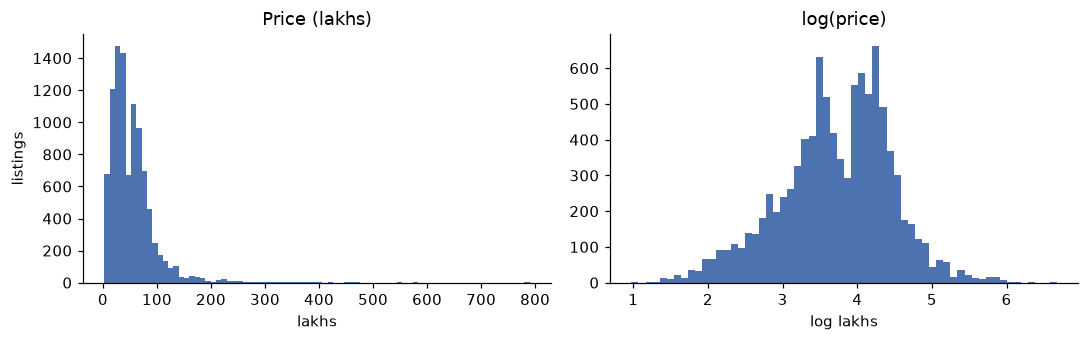

min           2.65
median       43.00
p05          10.50
p95         125.00
max         790.00
skew          3.46
log_skew     -0.29
dtype: float64

In [5]:
price = dedup["price"]
metrics["target"] = {
    "min": float(price.min()), "median": float(price.median()), "p05": float(price.quantile(.05)), "p95": float(price.quantile(.95)),
    "max": float(price.max()), "skew": float(price.skew()), "log_skew": float(np.log(price).skew()),
}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(price, bins=80, color="#4C72B0"); ax[0].set(title="Price (lakhs)", xlabel="lakhs", ylabel="listings")
ax[1].hist(np.log(price), bins=60, color="#4C72B0"); ax[1].set(title="log(price)", xlabel="log lakhs")
plt.tight_layout(); plt.savefig(FIG / "target_distribution.png"); plt.show()
pd.Series(metrics["target"]).round(2)

### 1.3 Categorical features: cardinality and the long tail of models

In [6]:
card = pd.DataFrame({
    "unique values": [dedup[c].nunique() for c in CATEGORICAL],
    "top value share": [dedup[c].value_counts(normalize=True).iloc[0] for c in CATEGORICAL],
}, index=CATEGORICAL).round(3)
mc = dedup["model"].value_counts()
metrics["cardinality"] = {
    "brands": int(dedup.brand.nunique()), "models": int(dedup.model.nunique()), "towns": int(dedup.town.nunique()),
    "models_lt5": int((mc < 5).sum()), "rows_in_models_lt5": int(mc[mc < 5].sum()),
    "models_singleton": int((mc == 1).sum()),
    "top_models": mc.head(8).to_dict(),
}
display(card)
pd.Series({k: v for k, v in metrics["cardinality"].items() if k != "top_models"})

,unique values,top value share
brand,50,0.316
model,1555,0.040
gear,2,0.645
fuel,4,0.803
town,107,0.106
leasing,2,0.959
condition,2,0.990
air_condition,2,0.980
power_steering,2,0.911
power_mirror,2,0.744


brands                  50
models                1555
towns                  107
models_lt5            1260
rows_in_models_lt5    1822
models_singleton       916
dtype: int64

### 1.4 What moves the price? Relationships with log(price)

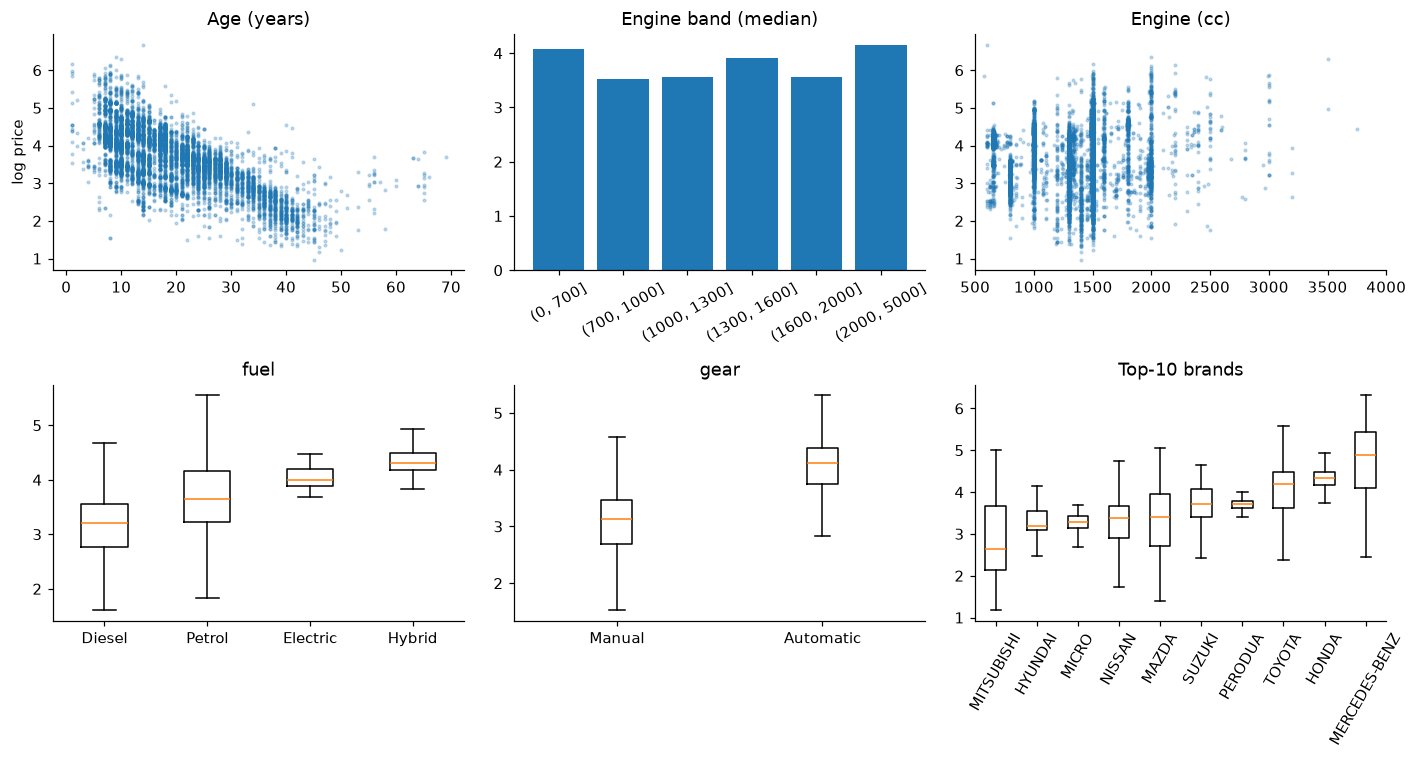

Spearman with log price: {'age': -0.655, 'engine_cc': 0.088}
Median price by fuel: {'Diesel': 24.8, 'Electric': 54.4, 'Hybrid': 73.8, 'Petrol': 38.5}
Median price by gear: {'Automatic': 61.5, 'Manual': 23.0}


In [7]:
d = dedup.assign(age=REFERENCE_YEAR - dedup.yom, log_price=np.log(dedup.price))
fig, ax = plt.subplots(2, 3, figsize=(13, 7))
ax[0, 0].scatter(d.age, d.log_price, s=3, alpha=.25); ax[0, 0].set(title="Age (years)", ylabel="log price")
cc_bins = pd.cut(d.engine_cc, [0, 700, 1000, 1300, 1600, 2000, 5000])
ccm = d.groupby(cc_bins, observed=True).log_price.median()
ax[0, 1].bar(range(len(ccm)), ccm.values); ax[0, 1].set_xticks(range(len(ccm)), [str(i) for i in ccm.index], rotation=30); ax[0, 1].set(title="Engine band (median)")
ax[0, 2].scatter(d.engine_cc, d.log_price, s=3, alpha=.25); ax[0, 2].set(title="Engine (cc)", xlim=(500, 4000))
for a, col in zip([ax[1, 0], ax[1, 1]], ["fuel", "gear"]):
    order = d.groupby(col).log_price.median().sort_values().index
    a.boxplot([d.loc[d[col] == k, "log_price"] for k in order], tick_labels=order, showfliers=False); a.set(title=col)
top = d.brand.value_counts().head(10).index
order = d[d.brand.isin(top)].groupby("brand").log_price.median().sort_values().index
ax[1, 2].boxplot([d.loc[d.brand == b, "log_price"] for b in order], tick_labels=order, showfliers=False)
ax[1, 2].set(title="Top-10 brands"); ax[1, 2].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(FIG / "relationships.png"); plt.show()

metrics["spearman_with_log_price"] = d[["age", "engine_cc"]].corrwith(d.log_price, method="spearman").round(3).to_dict()
metrics["median_price_by_fuel"] = d.groupby("fuel").price.median().round(1).to_dict()
metrics["median_price_by_gear"] = d.groupby("gear").price.median().round(1).to_dict()
print("Spearman with log price:", metrics["spearman_with_log_price"])
print("Median price by fuel:", metrics["median_price_by_fuel"])
print("Median price by gear:", metrics["median_price_by_gear"])

### 1.5 Does the listing date matter? (import ban lifted 1 Feb 2025)

In [8]:
d["month"] = pd.to_datetime(d["date"]).dt.to_period("M").astype(str)
by_month = d.groupby("month").agg(listings=("price", "size"), median_price=("price", "median"))
# Compare like with like: log price relative to the mean of the same make+model+year,
# using only make+model+year groups with at least 10 listings
grp_n = d.groupby(["brand", "model", "yom"]).log_price.transform("size")
d["rel"] = d.log_price - d.groupby(["brand", "model", "yom"]).log_price.transform("mean")
by_month["mean_pct_vs_same_model_year"] = d[grp_n >= 10].groupby("month").rel.mean().pipe(lambda s: (np.exp(s) - 1) * 100).round(2)
metrics["by_month"] = by_month.reset_index().to_dict(orient="records")
by_month

,listings,median_price,mean_pct_vs_same_model_year
month,,,
2024-12,2869,43.00,0.41
2025-01,4471,42.50,-0.26
2025-02,2430,43.75,-0.09


**No month-to-month drift.** Within the same make, model and year, listings in December, January and February differ by less than ±0.5 % on average. Asking prices did not move in the days after the import ban was lifted on 1 Feb 2025; the first imported cars only reached Colombo Port on 25 Feb 2025. `date` is therefore not used as a feature, and this dataset cannot say anything about post-liberalisation prices (§8).

### 1.6 From analysis to modelling decisions

| Finding (evidence above) | Decision |
|---|---|
| Price skew 3.46. log(price) skew −0.29 | Model **log(price)**. Report errors in lakhs and as percentages |
| 1,555 models, 1,260 with fewer than 5 listings (916 seen once). 50 brands, 107 towns | Need **categorical-aware** learners (CatBoost target statistics, LightGBM categorical splits). One-hot encoders pool rare levels (`min_frequency=5`). Brand gives a fallback for rare models |
| Age is the strongest numeric signal (Spearman −0.66) and its effect is curved | Tree ensembles, which fit non-linear depreciation without hand-made terms |
| Automatic median 61.5 vs manual 23.0 lakhs. Hybrids 73.8 vs petrol 38.5 | Keep gear and fuel. Interpret them *conditionally* (§6.2), because hybrids are also newer and particular models |
| Mileage = 11,000 × age in every row | **Drop mileage** |
| 613 groups of identical listings (mostly reposts) | **Group-aware** split and cross-validation |
| No price drift by month | No time-series model. `date` dropped |

## 2 · Model selection

The analysis describes a **tabular regression problem with many high-cardinality categorical features** (brand, model, town), a long tail of rare models, a skewed target, non-linear depreciation and only two usable numeric features. That rules some approaches in and others out.

| Candidate | Role | Why it is (or is not) suitable here |
|---|---|---|
| **CatBoost** | Main candidate | Built for categorical data. It encodes `model` (1,555 values) with *ordered target statistics*, which avoids one-hot explosion and target leakage. It also builds feature combinations automatically, such as brand × model. The brief suggests it "if your dataset has categorical features", which is exactly this case. |
| **LightGBM** | Main candidate | A gradient-boosting library with native categorical splits (it groups categories by gradient statistics). Fast, so it is cheap to cross-validate. Its errors differ from CatBoost's, which matters for stacking. |
| **Stacking** | Main candidate | A positive linear meta-learner over XGBoost, CatBoost and LightGBM. Each base model encodes categories differently (one-hot, ordered target statistics, gradient-sorted splits), so their errors are partly independent, and stacking can cancel some of them. |
| Market-comparable median | Baseline (existing practice) | What a buyer does by hand on ikman or Riyasewana: the median price of the same make, model and year, backing off to make+model, then make. |
| Ridge regression (one-hot) | Baseline (existing approach) | Multiple linear regression is what the Sri Lankan studies used (Jayadeera & Jayamanne, 2019; Basnayaka, 2023). Run on log price, it is the strongest fair linear baseline. |
| Random Forest, XGBoost (one-hot) | Baselines (existing approaches) | The Part 1 models and the most common approaches in the literature and in public repositories on this same dataset. |
| ARIMA + RF hybrid | **Not used** | The brief suggests it for weather time series. These listings are a cross-section of two months with no per-car time series, and §1.5 shows no price drift across the months. |
| Neural networks / deep learning | **Not used** | Out of scope for this module per the brief. Also, on ~10k tabular rows, boosted trees are the stronger and more interpretable choice (Jamalamadaka, 2025). |

**Selection rule.** The final model is chosen on 5-fold cross-validated MAPE on the training part. The test set reports the chosen model's performance and is never used to choose it. A simpler model is preferred unless the more complex one is *reliably* better: better on average by more than one standard error of the paired per-fold differences. Every model is scored on the same five folds, so differences are compared fold by fold (§3.1).

> *Disclosure.* Before the comparison, the rule was written as "simpler model wins if within one fold standard deviation of the best". After seeing the CV table, that rule turned out to be the wrong statistic: the fold SD mostly measures how hard each fold is, which affects every model equally, so it hides consistent differences. The paired comparison is the standard correction. Both versions are reported in §3.1 so the reader can see what each one selects.

### 2.1 Preprocessing and split

* **Features** (`vehicle_model.py`): `age = 2025 − YOM` (depreciation follows age, not calendar year), `engine_cc`, and eleven upper-cased, stripped categoricals. **Mileage is dropped** because it is a deterministic copy of age (§1.1). `date` is dropped because it shows no price drift (§1.5).
* **Target**: `log(price)`. That gives a near-symmetric target (§1.2), makes the loss penalise *relative* errors (a Rs 5 lakh miss on an Alto matters more than on a Land Cruiser), and keeps predictions positive.
* **Missing values and scaling**: the dataset has no nulls. The front end validates its inputs, the boosters handle missing values natively, and the one-hot encoders ignore unseen categories, so a new model name cannot crash a prediction. Only Ridge needs scaling, so `engine_cc` and `age` are standardised there. The tree models are scale-invariant.
* **Split**: exact duplicates are removed. Then a **grouped** 80/20 split by `car_id` keeps every repost of the same car on the same side, so the test set measures generalisation to *unseen cars*, not memorised reposts. Model comparison and every design check use 5-fold `GroupKFold` on the training part only. The test set is touched once.
* **Inference sample** (kept from the activity): one recent listing is removed before any split, so the model never sees it.

In [9]:
data = dedup.reset_index(drop=True)

# Hold out one listing for single-sample inference: the most recent Toyota Aqua (a common hybrid)
aqua = data[(data.brand == "TOYOTA") & (data.model == "AQUA")].sort_values("date")
inference_row = data.loc[[aqua.index[-1]]]
# remove the held-out car (and any reposts of it) before splitting
data = data[data.car_id != inference_row.car_id.iloc[0]].reset_index(drop=True)

X_all, y_all, groups = add_features(data), np.log(data.price.values), data.car_id.values
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr, te = next(gss.split(X_all, y_all, groups))
X_tr, X_te, y_tr, y_te, g_tr = X_all.iloc[tr], X_all.iloc[te], y_all[tr], y_all[te], groups[tr]
folds = list(GroupKFold(n_splits=5).split(X_tr, y_tr, g_tr))
metrics["split"] = {"train": len(tr), "test": len(te), "dedup_rows": len(dedup),
                    "test_rows_model_unseen_in_train": int((~X_te.model.isin(set(X_tr.model))).sum())}
print(metrics["split"])
inference_row[INPUT_COLUMNS + ["price", "date"]]

{'train': 7817, 'test': 1952, 'dedup_rows': 9770, 'test_rows_model_unseen_in_train': 217}


,brand,model,yom,engine_cc,gear,fuel,town,leasing,condition,air_condition,power_steering,power_mirror,power_window,price,date
6914,TOYOTA,AQUA,2012,1460.0,Automatic,Hybrid,Boralesgamuwa,No Leasing,USED,Available,Available,Available,Available,70.95,2025-02-05


### 2.2 Hyperparameters: designed, not defaulted

| Model | Parameter | Default | Chosen | Reasoning |
|---|---|---|---|---|
| CatBoost | `depth` | 6 | **6, 8 or 10, chosen in §2.3** | Price depends on interactions (model × age × engine). Depth 8 was the designed value. §2.3 checks it against one step either side. |
| | `learning_rate` / `iterations` | auto / 1000 | **0.08 / set by §2.3** | A moderate step. The number of trees is read off the validation curve, not guessed. |
| | `l2_leaf_reg` | 3 | **5** | Stronger shrinkage of leaf values, because 80 % of models have fewer than 5 listings. |
| | `one_hot_max_size` | auto | **4** | Low-cardinality fields (gear, fuel, leasing, equipment) are one-hot. Brand, model and town use ordered target statistics. |
| | `bootstrap_type` / `subsample` | MVS (CPU) | **Bernoulli / 0.8** | Plain uniform row subsampling at a fixed rate: simple to reason about, and it decorrelates trees. |
| LightGBM | `num_leaves` / `max_depth` | 31 / none | **31 or 48, chosen in §2.3 / 10** | A depth cap so leaf-wise growth cannot build very deep branches for rare models. |
| | `learning_rate` / `n_estimators` | 0.1 / 100 | **0.03 / set by §2.3** | Slow learning with many trees. |
| | `min_child_samples` | 20 | **10** | Lets common models (Alto, Vitz, Wagon R) get their own leaves. |
| | `cat_smooth` / `min_data_per_group` | 10 / 100 | **20 / 20** | Smooths category statistics towards the prior, but still allows a category split with 20 cars. |
| | `subsample` / `colsample_bytree` | 1 / 1 | **0.8 / 0.8** | Bagging rows and features. |
| XGBoost | `max_depth` / `learning_rate` / `n_estimators` | 6 / 0.3 / 100 | **7 / 0.05 / 1200** | Deeper trees for interactions across one-hot columns, with a slow learning rate and many trees. |
| | `subsample` / `colsample_bytree` / `min_child_weight` | 1 / 1 / 1 | **0.8 / 0.7 / 3** | Each tree sees 70 % of the one-hot columns. A leaf needs 3 cars' worth of evidence. |
| Random Forest | `n_estimators` / `max_features` / `min_samples_leaf` | 100 / 1.0 / 1 | **500 / 0.3 / 2** | Stable averages. Sampling 30 % of the features per split decorrelates trees on a wide one-hot matrix. A leaf of 2 avoids memorising one listing. |
| Ridge | `alpha` | 1.0 | **3.0** | A one-hot design with hundreds of columns needs more shrinkage. |
| One-hot encoders | `min_frequency` | none | **5** | Models seen fewer than 5 times are pooled as "infrequent" instead of getting a column fitted on 1–4 rows. |

In [10]:
CAT_IDX = [FEATURES.index(c) for c in CATEGORICAL]

def make_catboost(depth, iterations):
    return CatBoostRegressor(depth=depth, learning_rate=0.08, iterations=iterations, l2_leaf_reg=5,
                             one_hot_max_size=4, bootstrap_type="Bernoulli", subsample=0.8,
                             loss_function="RMSE", cat_features=CAT_IDX, random_seed=SEED,
                             verbose=0, allow_writing_files=False, thread_count=-1)

def lgb_params(num_leaves, n_estimators):
    return dict(num_leaves=num_leaves, max_depth=10, learning_rate=0.03, n_estimators=n_estimators,
                min_child_samples=10, cat_smooth=20, min_data_per_group=20, max_cat_to_onehot=4,
                subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                random_state=SEED, verbose=-1)

def onehot_pre(scale=False):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5), CATEGORICAL),
        ("num", StandardScaler() if scale else "passthrough", NUMERIC)])

def scores(y_log, p_log):
    t, p = np.exp(y_log), np.exp(p_log)
    return {"MAE (lakhs)": mean_absolute_error(t, p), "MAPE %": float(np.mean(np.abs(p - t) / t) * 100),
            "MdAPE %": float(np.median(np.abs(p - t) / t) * 100),
            "RMSE (lakhs)": float(np.sqrt(mean_squared_error(t, p))), "R² (price)": r2_score(t, p),
            "R² (log price)": r2_score(y_log, p_log)}

### 2.3 Checking the key design choices with grouped cross-validation
This checks the reasoning rather than running a blind grid search. Tree depth (CatBoost) and leaf count (LightGBM) are tried at the designed value and one step either side, on 3 training folds. The validation curve then shows where extra trees stop helping. The chosen tree count is the mean best iteration, rounded up to the next hundred. *Caveat:* the check reuses three of the five CV folds used in §3, so the CatBoost and LightGBM CV scores (and the stack's) are slightly optimistic. The untouched test set confirms the ranking.

In [11]:
check_rows = []
for depth in [6, 8, 10]:
    best_it, best = [], []
    for f_tr, f_va in folds[:3]:
        m = make_catboost(depth, 5000).fit(X_tr.iloc[f_tr], y_tr[f_tr], eval_set=(X_tr.iloc[f_va], y_tr[f_va]))
        curve = m.get_evals_result()["validation"]["RMSE"]
        best_it.append(int(np.argmin(curve)) + 1); best.append(min(curve))
    check_rows.append({"model": "CatBoost", "setting": f"depth={depth}", "val RMSE (log)": np.mean(best), "best iteration": np.mean(best_it)})
for nl in [31, 48]:
    best_it, best = [], []
    for f_tr, f_va in folds[:3]:
        m = LGBModel(**lgb_params(nl, 5000))
        m.categories = {c: sorted(X_tr.iloc[f_tr][c].unique().tolist()) for c in CATEGORICAL}
        import lightgbm as lgb
        r = lgb.LGBMRegressor(**lgb_params(nl, 5000)).fit(
            m._frame(X_tr.iloc[f_tr]), y_tr[f_tr], eval_set=[(m._frame(X_tr.iloc[f_va]), y_tr[f_va])])
        curve = np.sqrt(r.evals_result_["valid_0"]["l2"])
        best_it.append(int(np.argmin(curve)) + 1); best.append(curve.min())
    check_rows.append({"model": "LightGBM", "setting": f"num_leaves={nl}", "val RMSE (log)": np.mean(best), "best iteration": np.mean(best_it)})
check = pd.DataFrame(check_rows).round(4)

cb_best = check[check.model == "CatBoost"].sort_values("val RMSE (log)").iloc[0]
lgb_best = check[check.model == "LightGBM"].sort_values("val RMSE (log)").iloc[0]
CB_DEPTH, CB_ITERS = int(cb_best.setting.split("=")[1]), int(np.ceil(cb_best["best iteration"] / 100) * 100)
LGB_LEAVES, LGB_TREES = int(lgb_best.setting.split("=")[1]), int(np.ceil(lgb_best["best iteration"] / 100) * 100)
metrics["design_check"] = check.to_dict(orient="records")
metrics["chosen"] = {"catboost_depth": CB_DEPTH, "catboost_iterations": CB_ITERS,
                     "lgb_num_leaves": LGB_LEAVES, "lgb_n_estimators": LGB_TREES}
print(metrics["chosen"])
check

{'catboost_depth': 6, 'catboost_iterations': 2900, 'lgb_num_leaves': 48, 'lgb_n_estimators': 800}


,model,setting,val RMSE (log),best iteration
0,CatBoost,depth=6,0.2130,2856.3333
1,CatBoost,depth=8,0.2147,1216.3333
2,CatBoost,depth=10,0.2161,772.0000
3,LightGBM,num_leaves=31,0.2181,1192.0000
4,LightGBM,num_leaves=48,0.2179,744.6667


**What the check changed.** The designed CatBoost depth of 8 lost to depth 6: validation RMSE 0.2130 for depth 6 vs 0.2147 for 8 and 0.2161 for 10, in log units. Deeper trees peaked earlier (~770 trees at depth 10) and then overfitted, while depth 6 kept improving to about 2,860 trees. CatBoost therefore uses **depth 6 with 2,900 trees**. Depth 6 happens to equal CatBoost's default, but here it is chosen by evidence against the designed alternative. The rest of CatBoost's configuration (learning rate, trees, L2, one-hot size, bootstrap) is non-default. With ~8k rows and mostly categorical inputs, shallower symmetric trees generalise better than the interaction argument alone suggested. For LightGBM, 31 and 48 leaves were effectively tied (0.2181 vs 0.2179). The check picked **48 leaves with 800 trees**, but the difference is negligible.

## 3 · Comparison on the same data: baselines vs chosen models

**3.1 Five-fold grouped cross-validation (training part), which decides the final model.** The stack's meta-learner is trained on out-of-fold predictions and scored with its own inner cross-validation, so its CV score is not optimistic.

In [12]:
MODELS = {
    "Market-comparable median": MarketComparable,
    "Ridge (one-hot)": lambda: make_pipeline(onehot_pre(scale=True), Ridge(alpha=3.0)),
    "Random Forest": lambda: make_pipeline(onehot_pre(), RandomForestRegressor(
        n_estimators=500, max_features=0.3, min_samples_leaf=2, n_jobs=-1, random_state=SEED)),
    "XGBoost": lambda: make_pipeline(onehot_pre(), XGBRegressor(
        n_estimators=1200, learning_rate=0.05, max_depth=7, subsample=0.8, colsample_bytree=0.7,
        min_child_weight=3, reg_lambda=1.0, n_jobs=-1, random_state=SEED)),
    "LightGBM": lambda: LGBModel(**lgb_params(LGB_LEAVES, LGB_TREES)),
    "CatBoost": lambda: make_catboost(CB_DEPTH, CB_ITERS),
}
STACK_BASE = ["XGBoost", "CatBoost", "LightGBM"]

oof = {n: np.zeros(len(y_tr)) for n in MODELS}
fold_scores = {n: [] for n in MODELS}
for name, factory in MODELS.items():
    for f_tr, f_va in folds:
        oof[name][f_va] = factory().fit(X_tr.iloc[f_tr], y_tr[f_tr]).predict(X_tr.iloc[f_va])
        fold_scores[name].append(scores(y_tr[f_va], oof[name][f_va]))

Z = np.column_stack([oof[n] for n in STACK_BASE])
meta = LinearRegression(positive=True)
oof["Stack (XGB+CatBoost+LGBM)"] = cross_val_predict(meta, Z, y_tr, cv=folds)   # meta never scores its own fit
fold_scores["Stack (XGB+CatBoost+LGBM)"] = [scores(y_tr[v], oof["Stack (XGB+CatBoost+LGBM)"][v]) for _, v in folds]
meta.fit(Z, y_tr)
metrics["stack_weights"] = dict(zip(STACK_BASE, np.round(meta.coef_, 3).tolist()))
metrics["stack_intercept"] = round(float(meta.intercept_), 4)

rows = []
for n, fs in fold_scores.items():
    fs = pd.DataFrame(fs)
    rows.append({"model": n, **fs.mean().to_dict(), "MAPE % sd": fs["MAPE %"].std(), "R² (price) sd": fs["R² (price)"].std()})
cv_table = pd.DataFrame(rows).set_index("model").round(3)
metrics["cv"] = cv_table.reset_index().to_dict(orient="records")
print("Stack weights:", metrics["stack_weights"], "intercept", metrics["stack_intercept"])
cv_table[["MAE (lakhs)", "MAPE %", "MAPE % sd", "MdAPE %", "R² (price)", "R² (price) sd", "R² (log price)"]]

Stack weights: {'XGBoost': 0.499, 'CatBoost': 0.379, 'LightGBM': 0.124} intercept -0.0085


,MAE (lakhs),MAPE %,MAPE % sd,MdAPE %,R² (price),R² (price) sd,R² (log price)
model,,,,,,,
Market-comparable median,7.604,23.266,1.288,4.189,0.704,0.044,0.759
Ridge (one-hot),7.131,15.968,0.656,8.344,0.804,0.063,0.887
Random Forest,5.695,13.347,0.561,5.820,0.848,0.050,0.911
XGBoost,5.441,12.717,0.554,5.965,0.879,0.064,0.919
LightGBM,5.759,13.472,0.462,6.612,0.872,0.065,0.914
CatBoost,5.846,13.424,0.589,6.960,0.856,0.052,0.916
Stack (XGB+CatBoost+LGBM),5.317,12.385,0.531,6.051,0.879,0.060,0.924


In [13]:
# Selection: prefer simpler models unless the better-scoring model wins reliably in a paired, fold-by-fold comparison.
COMPLEXITY = ["Market-comparable median", "Ridge (one-hot)", "Random Forest", "XGBoost", "LightGBM",
              "CatBoost", "Stack (XGB+CatBoost+LGBM)"]
fold_mape = pd.DataFrame({n: [s["MAPE %"] for s in fold_scores[n]] for n in COMPLEXITY}, index=[f"fold {i+1}" for i in range(5)])
best = fold_mape.mean().idxmin()
paired = []
for m in COMPLEXITY:
    diff = fold_mape[m] - fold_mape[best]                # positive = m is worse than best
    se = diff.std(ddof=1) / np.sqrt(len(diff)) if m != best else 0.0
    paired.append({"model": m, "mean MAPE gap vs best": diff.mean(), "folds where best wins": int((diff > 0).sum()),
                   "SE of gap": se, "not reliably worse": bool(diff.mean() <= se)})
paired = pd.DataFrame(paired).set_index("model").round(3)
FINAL = next(m for m in COMPLEXITY if paired.loc[m, "not reliably worse"])
# The originally written rule (one fold SD of the best), reported for transparency
tol = cv_table.loc[best, "MAPE % sd"]
original_rule_pick = next(m for m in COMPLEXITY if cv_table.loc[m, "MAPE %"] <= cv_table.loc[best, "MAPE %"] + tol)
metrics["fold_mape"] = fold_mape.round(3).to_dict(orient="list")
metrics["selection"] = {"lowest_cv_mape": best, "final_paired_rule": FINAL, "original_one_sd_rule_pick": original_rule_pick,
                        "paired": paired.reset_index().to_dict(orient="records")}
display(fold_mape.round(2))
print(f"Final model (paired rule): {FINAL}   |   originally written one-SD rule would pick: {original_rule_pick}")
paired

,Market-comparable median,Ridge (one-hot),Random Forest,XGBoost,LightGBM,CatBoost,Stack (XGB+CatBoost+LGBM)
fold 1,24.18,16.28,13.55,12.62,13.46,12.87,12.10
fold 2,24.84,16.57,14.15,13.62,14.18,14.13,13.19
fold 3,22.19,15.01,12.63,12.17,12.89,12.76,11.78
fold 4,23.32,15.57,13.14,12.39,13.43,13.72,12.34
fold 5,21.80,16.41,13.25,12.77,13.41,13.65,12.52


Final model (paired rule): Stack (XGB+CatBoost+LGBM)   |   originally written one-SD rule would pick: XGBoost


,mean MAPE gap vs best,folds where best wins,SE of gap,not reliably worse
model,,,,
Market-comparable median,10.880,5,0.490,False
Ridge (one-hot),3.583,5,0.192,False
Random Forest,0.961,5,0.129,False
XGBoost,0.332,5,0.081,False
LightGBM,1.087,5,0.078,False
CatBoost,1.039,5,0.103,False
Stack (XGB+CatBoost+LGBM),0.000,0,0.000,True


**3.2 Held-out test set (unseen cars, touched once).** Every model is refitted on the full training part.

In [14]:
test_pred, fitted, fit_time = {}, {}, {}
for name, factory in MODELS.items():
    t0 = time.time(); fitted[name] = factory().fit(X_tr, y_tr); fit_time[name] = time.time() - t0
    test_pred[name] = fitted[name].predict(X_te)
stack = StackedModel({n: fitted[n] for n in STACK_BASE}, metrics["stack_weights"], metrics["stack_intercept"])
fitted["Stack (XGB+CatBoost+LGBM)"] = stack
test_pred["Stack (XGB+CatBoost+LGBM)"] = stack.predict(X_te)
fit_time["Stack (XGB+CatBoost+LGBM)"] = sum(fit_time[n] for n in STACK_BASE)

test_table = pd.DataFrame({n: scores(y_te, p) for n, p in test_pred.items()}).T
test_table["fit time (s)"] = pd.Series(fit_time)
test_table = test_table.round(3)
metrics["test"] = test_table.reset_index(names="model").to_dict(orient="records")
test_table

,MAE (lakhs),MAPE %,MdAPE %,RMSE (lakhs),R² (price),R² (log price),fit time (s)
Market-comparable median,7.629,23.601,4.013,21.046,0.743,0.746,0.003
Ridge (one-hot),7.069,16.332,8.024,16.421,0.844,0.870,0.048
Random Forest,5.820,13.762,5.794,14.820,0.873,0.898,1.085
XGBoost,5.716,13.283,6.289,13.885,0.888,0.910,1.913
LightGBM,6.065,14.009,6.411,14.609,0.876,0.900,5.592
CatBoost,6.167,14.187,6.928,14.492,0.878,0.902,4.916
Stack (XGB+CatBoost+LGBM),5.617,13.040,6.280,13.672,0.892,0.912,12.421


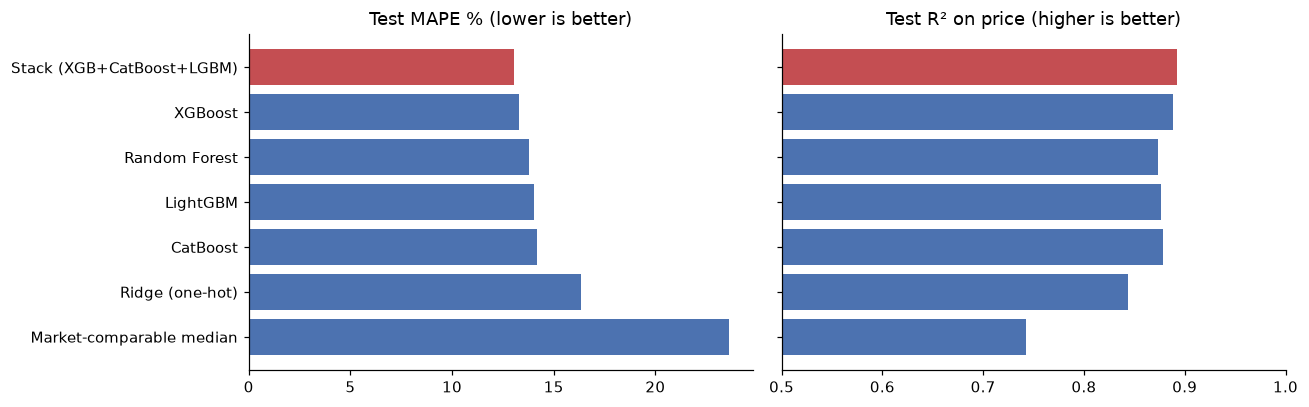

In [15]:
order = test_table.sort_values("MAPE %", ascending=False)
colors = ["#C44E52" if i == FINAL else "#4C72B0" for i in order.index]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].barh(order.index, order["MAPE %"], color=colors); ax[0].set(title="Test MAPE % (lower is better)")
ax[1].barh(order.index, order["R² (price)"], color=colors)
ax[1].set(title="Test R² on price (higher is better)", xlim=(0.5, 1)); ax[1].set_yticklabels([])
plt.tight_layout(); plt.savefig(FIG / "model_comparison.png"); plt.show()

**Reading the comparison**

* **Ranking (CV and test agree):** the stack is best (CV MAPE 12.4 %, test 13.0 %, test R² 0.892), then XGBoost (12.7 % / 13.3 %), then Random Forest, CatBoost and LightGBM, which are close together (CV 13.3–13.5 %). Ridge regression is clearly behind (16.0 % / 16.3 %), and the market-comparable median is last on mean error (23.3 % / 23.6 %).
* **The stack wins in all five folds** against every other model (table above). Its edge over XGBoost is small, 0.33 MAPE points on average, but consistent: the standard error of that gap is only 0.08.
* **Test is slightly worse than CV for every model** (about +0.3 to +0.8 points). That is normal sampling variation for an unseen 20 % slice. The ordering holds, so the comparison is not an artefact of one split.
* **A surprise worth explaining:** the market-comparable median has the *lowest median error* of all (MdAPE 4.0 % vs the stack's 6.3 %), yet the worst mean error. When a car is common, sellers price it by copying other listings, so the median of the same make, model and year is almost exactly right. When a car is rare or unseen, there is nothing to copy, and the median falls back to a whole-brand average and misses badly (§6.3). The ML models trade a little accuracy on common cars for far better accuracy on the long tail. §8 discusses how a hybrid could keep both.
* **R² on price vs on log price:** R² on price is dominated by the few luxury cars (up to 790 lakhs), so RMSE and R²(price) reward getting Mercedes and BMWs right. MAPE weighs every car equally. Both are reported, and the stack leads on both.

**3.3 Bagging, boosting, voting and stacking side by side.** The table above already contains a bagging model (Random Forest), three boosting models and a stack. Two more make each ensemble technique explicit:

* **Plain bagging:** `BaggingRegressor` over full-depth decision trees, each trained on a bootstrap sample and allowed to use every feature. Random Forest is bagging *plus* a random feature subset at each split, which makes the trees less alike, so comparing the two isolates what that extra randomness buys.
* **Voting:** the stack's three boosters averaged with fixed equal weights, which is what sklearn's `VotingRegressor` computes. It reuses the already-fitted boosters (`StackedModel` with weights ⅓), so the only difference from the stack is learned vs fixed weights.

Both are added after model selection, so they do not change the final choice; they are here for comparison.

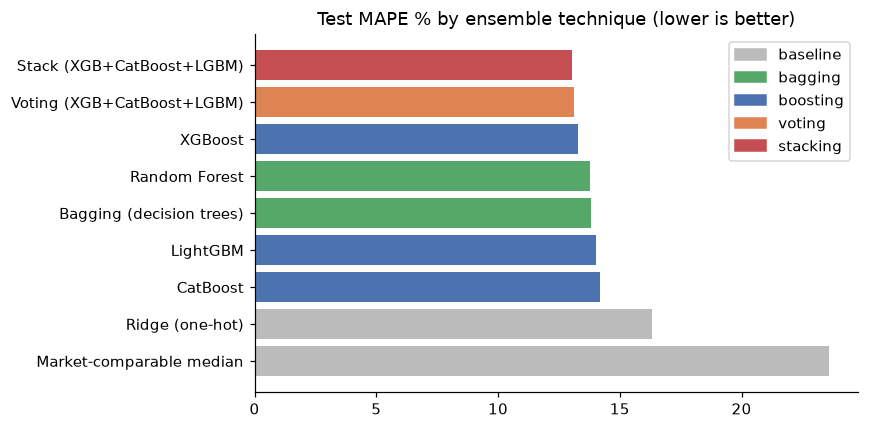

,technique,CV MAPE %,CV MAPE % sd,test MAPE %,test MdAPE %,test R² (price),fit time (s)
model,,,,,,,
Market-comparable median,baseline: lookup,23.266,1.288,23.601,4.013,0.743,0.003
Ridge (one-hot),baseline: linear,15.968,0.656,16.332,8.024,0.844,0.048
Bagging (decision trees),bagging,13.322,0.822,13.821,5.366,0.872,0.663
Random Forest,bagging + feature sampling,13.347,0.561,13.762,5.794,0.873,1.085
XGBoost,boosting,12.717,0.554,13.283,6.289,0.888,1.913
LightGBM,boosting,13.472,0.462,14.009,6.411,0.876,5.592
CatBoost,boosting,13.424,0.589,14.187,6.928,0.878,4.916
Voting (XGB+CatBoost+LGBM),voting (equal weights),12.480,0.521,13.130,6.356,0.891,12.421
Stack (XGB+CatBoost+LGBM),stacking (learned weights),12.385,0.531,13.040,6.280,0.892,12.421


In [16]:
BAG = "Bagging (decision trees)"
VOTE = "Voting (XGB+CatBoost+LGBM)"
bagging = lambda: make_pipeline(onehot_pre(), BaggingRegressor(
    DecisionTreeRegressor(min_samples_leaf=2), n_estimators=100, n_jobs=-1, random_state=SEED))
oof[BAG] = np.zeros(len(y_tr)); fold_scores[BAG] = []
for f_tr, f_va in folds:
    oof[BAG][f_va] = bagging().fit(X_tr.iloc[f_tr], y_tr[f_tr]).predict(X_tr.iloc[f_va])
    fold_scores[BAG].append(scores(y_tr[f_va], oof[BAG][f_va]))
t0 = time.time(); fitted[BAG] = bagging().fit(X_tr, y_tr); fit_time[BAG] = time.time() - t0
test_pred[BAG] = fitted[BAG].predict(X_te)

oof[VOTE] = np.mean([oof[n] for n in STACK_BASE], axis=0)
fold_scores[VOTE] = [scores(y_tr[v], oof[VOTE][v]) for _, v in folds]
fitted[VOTE] = StackedModel({n: fitted[n] for n in STACK_BASE}, {n: 1 / len(STACK_BASE) for n in STACK_BASE}, 0.0)
test_pred[VOTE] = fitted[VOTE].predict(X_te)
fit_time[VOTE] = fit_time["Stack (XGB+CatBoost+LGBM)"]

TECHNIQUE = {"Market-comparable median": "baseline: lookup", "Ridge (one-hot)": "baseline: linear",
             BAG: "bagging", "Random Forest": "bagging + feature sampling",
             "XGBoost": "boosting", "LightGBM": "boosting", "CatBoost": "boosting",
             VOTE: "voting (equal weights)", "Stack (XGB+CatBoost+LGBM)": "stacking (learned weights)"}
ens = pd.DataFrame([{"model": n, "technique": t,
                     "CV MAPE %": np.mean([s["MAPE %"] for s in fold_scores[n]]),
                     "CV MAPE % sd": np.std([s["MAPE %"] for s in fold_scores[n]], ddof=1),
                     **{f"test {k}": v for k, v in scores(y_te, test_pred[n]).items() if k in ("MAPE %", "MdAPE %", "R² (price)")},
                     "fit time (s)": fit_time[n] if n in fit_time else np.nan} for n, t in TECHNIQUE.items()]).set_index("model").round(3)
metrics["ensembles"] = ens.reset_index().to_dict(orient="records")

order = ens.sort_values("test MAPE %", ascending=False)
palette = {"baseline": "#BBBBBB", "bagging": "#55A868", "boosting": "#4C72B0", "voting": "#DD8452", "stacking": "#C44E52"}
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(order.index, order["test MAPE %"], color=[palette[t.split(" ")[0].strip(":")] for t in order.technique])
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in palette.items()], loc="upper right"); ax.set(title="Test MAPE % by ensemble technique (lower is better)")
plt.tight_layout(); plt.savefig(FIG / "ensemble_comparison.png"); plt.show()
ens

**Reading the ensemble comparison**

* **Plain bagging vs Random Forest:** nearly identical on mean error (CV 13.32 % vs 13.35 %, test 13.8 % vs 13.8 %). Random sampling of features at each split did not lower the error here. Instead it steadied the error across folds (fold SD 0.56 vs 0.82 points), because with every feature available, the bagged trees keep splitting on age and brand and end up alike. Both bagging models have the lowest *median* error of the ML models (5.4–5.8 %): averaging deep trees is very good on common cars.
* **Boosting beats bagging on mean error.** XGBoost (CV 12.7 %) is the best single model. Shallow trees fitted in sequence to the remaining errors handle the long tail of rare models better than averaged deep trees.
* **Voting vs stacking: the same three boosters, different weights.** Equal-weight voting already beats every single model (CV 12.48 %, test 13.13 %). Learning the weights out of fold (0.50 / 0.38 / 0.12) adds a further 0.1 point (CV 12.39 %, test 13.04 %). So most of the stack's gain comes from combining models whose errors differ, and only a small part from the learned weights.
* The final model is unchanged. These two were added after selection, and neither beats the stack.

## 4 · Comparison with existing approaches

### 4.1 Published and public work

| Study | Data | Method(s) | Reported result | Comparable to ours? |
|---|---|---|---|---|
| Jayadeera & Jayamanne (2019), *ICOBI*, NSBM Green University | ~200 ikman.lk Toyota Corolla listings (Sri Lanka) | Multiple linear regression, RF, decision tree, gradient boosting | R²: MLR 0.83, RF 0.84, DT 0.89, GB 0.70 (Fig. 8) | One model of car, 200 rows, random split. Ours covers 50 brands and 1,555 models on unseen cars |
| Basnayaka (2023), MSc dissertation, Informatics Institute of Technology | Sri Lankan used-car dataset from Kaggle | MLR, RF, Extra Trees, GB, LightGBM, XGBoost, simple-average ensemble | "Almost all regressors gave accuracy close to 90 % except multiple linear regression" (abstract) | The metric behind "accuracy" is not stated in the abstract. Same conclusion as ours: boosted and ensemble models beat linear regression |
| Public repository *sri-lanka-vehicle-price-ml* (2026) | **Same Kaggle v3 dataset** | RF vs XGBoost on raw price, one-hot | RF R² 0.812, MAE 5.89. XGBoost R² 0.808, MAE 6.98 | Random split (reposts can leak), and mileage treated as a real feature |
| Public repository *Sri_Lankan-Vehicle-Price-Predictor* (2026) | Sri Lankan vehicle listings with the same fields (appears to be the same data; not confirmed) | CatBoost + quantile models | MAPE ≈ 13.5 %, R² ≈ 0.92, 80 % interval coverage ≈ 74 % | Random 80/20 holdout, where reposts can leak. Its R² is higher than ours (0.892), so this is not like-for-like |
| Jamalamadaka (2025), *National High School Journal of Science* | 8,128 Indian CarDekho listings (with real mileage) | 11 classical models + 3 neural nets | LightGBM R² 0.965, CatBoost 0.961, XGBoost 0.958, RF 0.958, linear 0.633. Best neural net 0.916 | Different market. Supports "boosted trees > linear > neural nets on tabular car data" |

### 4.2 How this work compares
* **Against the Sri Lankan studies,** the conclusion agrees: tree ensembles beat linear regression. Here the gap is 3.3 MAPE points on unseen cars (Ridge 16.3 % vs stack 13.0 %). This work goes further by covering every make, model and town in the market rather than one car model.
* **Against public work on the same data,** our test R² on price (0.892) is higher than the RF/XGBoost repository (0.81), and our MAE is similar (5.62 vs 5.89 lakhs). We get there **without mileage**, which is synthetic, and on a **grouped split** where reposted cars cannot leak into the test set. That is a harder and more honest evaluation. Against the CatBoost repository: our MAPE (13.0 %) is in line with its ≈13.5 %, and its R² (≈0.92) is higher than ours (0.892). Part of that gap is plausibly its random split, which lets reposted cars appear in both train and test. We cannot confirm that without re-running their code. Our 80 % range is calibrated (79.4 % coverage on test), where theirs reached 74 %.
* **Against existing practice** (pricing from comparable listings), the model cuts mean percentage error from 23.6 % to 13.0 %, and on cars whose model never appeared in training, median error from 46.3 % to 14.3 % (§6.3).
* **A caution:** numbers across different datasets and splits are not like-for-like. The Indian study's R² of 0.96 comes from a market with real mileage, so it should not be read as "their model is better".

## 5 · Why the chosen approach is effective

**Final model: a stack of XGBoost (one-hot), CatBoost (ordered target statistics) and LightGBM (categorical splits), combined by a positive linear meta-learner** (weights 0.50 / 0.38 / 0.12). The case for it:

1. **It has the lowest error, and the lead is reliable.** It is best on cross-validated MAPE (12.4 %), and it beats the strongest single model, XGBoost, in **5 of 5 folds**. The 0.33-point gap is four times its standard error. The untouched test set confirms the ranking (13.0 % vs 13.3 %).
2. **It suits the data's main difficulty, the categories.** Each base model handles the 1,555-value `model` field differently. One-hot XGBoost learns sharp effects for frequent models. CatBoost's target statistics give rare models a sensible prior. LightGBM groups categories by gradient. Because their errors differ, the combination is better than any single one. The meta-learner gives every model a non-zero weight, which shows each adds something.
3. **It is far better than existing approaches where it matters.** It cuts mean error by 10.6 points against comparable-listing pricing, and by 3.3 points against the linear regression used in the Sri Lankan studies. On cars whose model it had never seen, median error is 14.3 % vs 46.3 % for comparables.
4. **It is honest about uncertainty.** Every prediction comes with an 80 % range built from out-of-fold errors, and on the test set 79.4 % of true prices fell inside it.
5. **It is cheap to run.** About 12 s to train on a laptop and milliseconds per prediction, which is fine for an interactive app.

**The cost, stated plainly:** the stack is three models instead of one, for a gain of about 0.3 MAPE points over XGBoost alone. It is harder to explain, and it depends on three libraries. That gain was judged worth having because it is consistent across every fold and the run-time cost is negligible. If simplicity mattered more, for example in a production system with strict maintenance limits, XGBoost alone would be the defensible fallback, at a cost of about 0.3 points of MAPE.

## 6 · Interpreting the output

### 6.1 Which inputs does the final model rely on? Permutation importance
Each input is shuffled in turn on the test set, and the increase in MAPE is measured. This explains the **final model itself**, whatever its type.

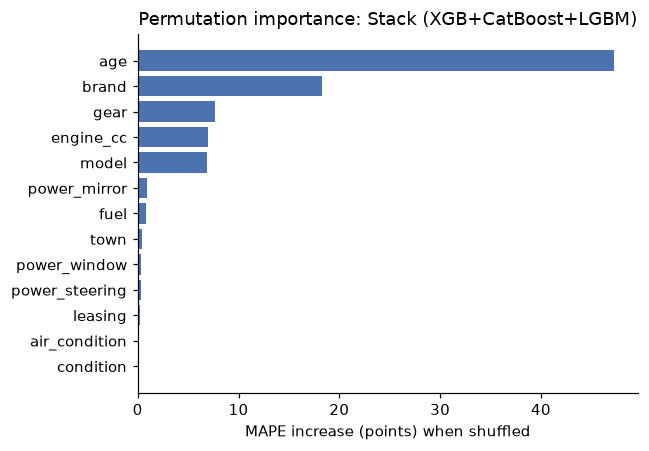

In [17]:
final_model = fitted[FINAL]
base_mape = scores(y_te, final_model.predict(X_te))["MAPE %"]
rng = np.random.default_rng(SEED)
perm = {}
for col in FEATURES:
    inc = []
    for _ in range(3):
        Xp = X_te.copy(); Xp[col] = rng.permutation(Xp[col].values)
        inc.append(scores(y_te, final_model.predict(Xp))["MAPE %"] - base_mape)
    perm[col] = float(np.mean(inc))
perm = pd.Series(perm).sort_values()
metrics["permutation_importance_mape_increase"] = perm.sort_values(ascending=False).round(2).to_dict()
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.barh(perm.index, perm.values, color="#4C72B0"); ax.set(title=f"Permutation importance: {FINAL}", xlabel="MAPE increase (points) when shuffled")
plt.tight_layout(); plt.savefig(FIG / "permutation_importance.png"); plt.show()

### 6.2 How do the drivers move the price? SHAP values (CatBoost component)
SHAP splits each CatBoost prediction into additive contributions in log-price units. A contribution of +0.10 means "about 10.5 % more expensive than the average car". CatBoost is one component of the stack, and it computes exact SHAP values natively, so it shows the *direction and shape* of each effect.

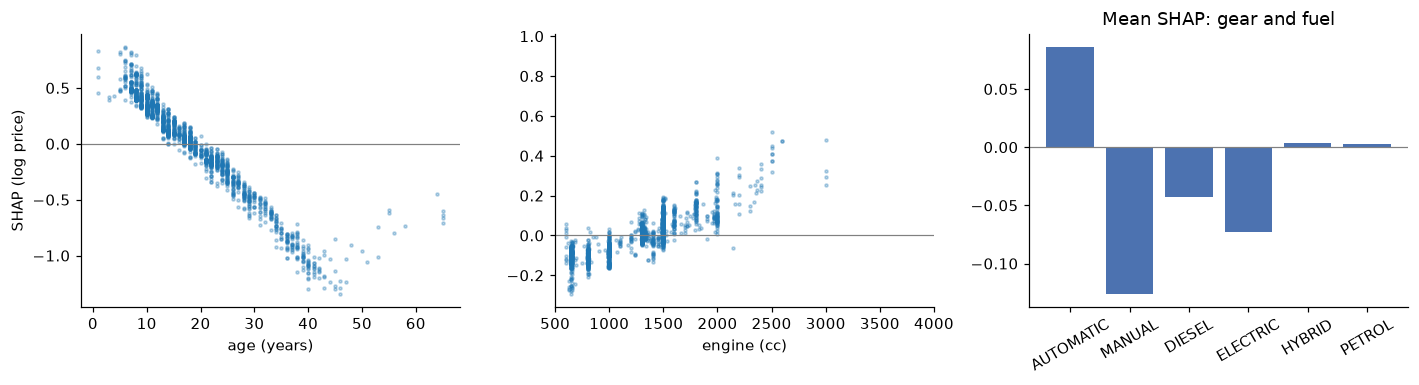

,mean SHAP (log),≈ % vs average car
age 0-5,0.565,76.0
age 6-10,0.435,54.5
age 11-15,0.234,26.4
age 16-20,0.025,2.6
age 21-30,-0.261,-23.0
age 31-60,-0.861,-57.7
fuel HYBRID,0.003,0.3
fuel PETROL,0.003,0.3
fuel DIESEL,-0.042,-4.2
fuel ELECTRIC,-0.073,-7.0


In [18]:
cb = fitted["CatBoost"]
cb_shap = cb.get_feature_importance(Pool(X_te, cat_features=CAT_IDX), type="ShapValues")[:, :-1]
S = pd.DataFrame(cb_shap, columns=FEATURES, index=X_te.index)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].scatter(X_te.age, S.age, s=4, alpha=.3); ax[0].set(xlabel="age (years)", ylabel="SHAP (log price)")
ax[1].scatter(X_te.engine_cc, S.engine_cc, s=4, alpha=.3); ax[1].set(xlabel="engine (cc)", xlim=(500, 4000))
gm = S.groupby(X_te.gear).gear.mean(); fm = S.groupby(X_te.fuel).fuel.mean()
ax[2].bar(list(gm.index) + list(fm.index), list(gm.values) + list(fm.values), color="#4C72B0"); ax[2].tick_params(axis="x", rotation=30)
ax[2].set(title="Mean SHAP: gear and fuel")
for a in ax: a.axhline(0, color="grey", lw=.8)
plt.tight_layout(); plt.savefig(FIG / "shap_dependence.png"); plt.show()

eff = {}
for lo, hi in [(0, 5), (6, 10), (11, 15), (16, 20), (21, 30), (31, 60)]:
    eff[f"age {lo}-{hi}"] = float(S.loc[X_te.age.between(lo, hi), "age"].mean())
for k in ["HYBRID", "PETROL", "DIESEL", "ELECTRIC"]:
    eff[f"fuel {k}"] = float(S.loc[X_te.fuel == k, "fuel"].mean())
for k in ["AUTOMATIC", "MANUAL"]:
    eff[f"gear {k}"] = float(S.loc[X_te.gear == k, "gear"].mean())
for k in ["ONGOING LEASE", "NO LEASING"]:
    eff[f"leasing {k}"] = float(S.loc[X_te.leasing == k, "leasing"].mean())
eff_t = pd.Series(eff).to_frame("mean SHAP (log)")
eff_t["≈ % vs average car"] = ((np.exp(eff_t.iloc[:, 0]) - 1) * 100).round(1)
metrics["shap_effects_pct"] = eff_t["≈ % vs average car"].to_dict()
metrics["shap_mean_abs"] = S.abs().mean().sort_values(ascending=False).round(4).to_dict()
eff_t.round(3)

### 6.2.1 SHAP for the final stack (the model the app uses)

The CatBoost SHAP above explains one component. The stack's prediction is intercept + Σ wᵢ · modelᵢ, and SHAP values add up, so the stack's exact SHAP is the same weighted sum of each base model's exact TreeSHAP (XGBoost's one-hot columns are summed back to the feature they came from). No sampling or approximation is involved, and the check below confirms that every prediction is recovered.

/Users/poornimakahatapitiya/Documents/Personal/Assignments/ML/part2-vehicle-price/.venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


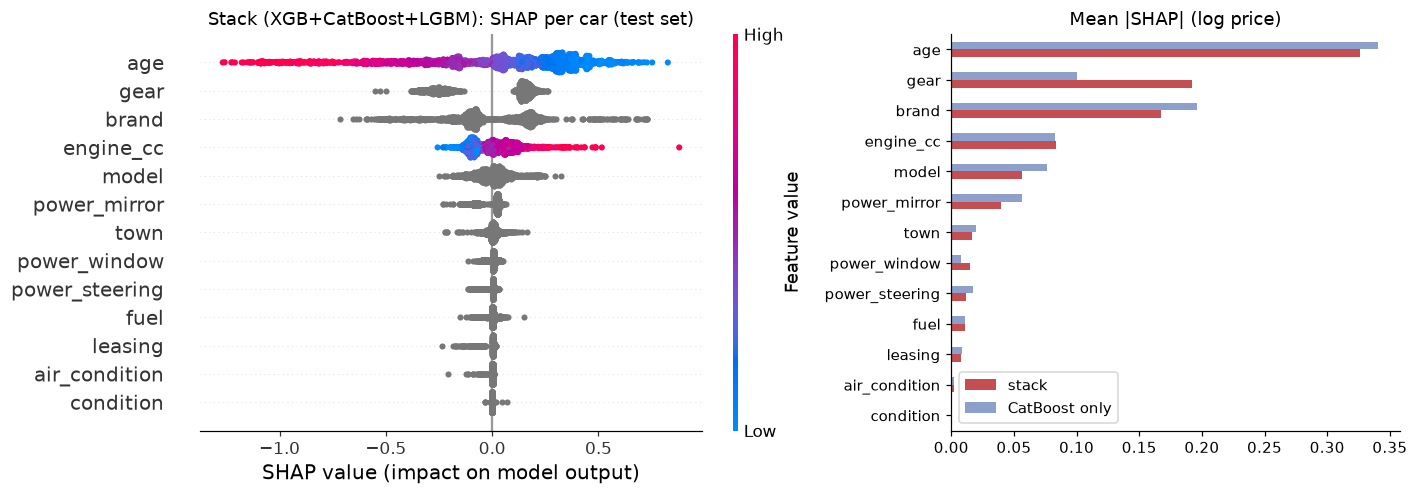

,stack,CatBoost only
age,0.326,0.341
gear,0.192,0.100
brand,0.167,0.196
engine_cc,0.084,0.083
model,0.056,0.076
power_mirror,0.040,0.056
town,0.017,0.020
power_window,0.015,0.008
power_steering,0.012,0.018
fuel,0.011,0.011


In [19]:
base_s, S_stack = explain(fitted[FINAL], X_te)
assert np.allclose(base_s + S_stack.sum(axis=1), test_pred[FINAL], atol=1e-4), "SHAP must add up to the prediction"
# Beeswarm colours points by feature value; that only means something for the numeric features, so categoricals show grey.
num_data = X_te.assign(**{c: np.nan for c in CATEGORICAL}).astype(float).values
ex = shap.Explanation(S_stack.values, base_values=np.full(len(S_stack), base_s), data=num_data, feature_names=FEATURES)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
plt.sca(ax[0]); shap.plots.beeswarm(ex, max_display=13, show=False, plot_size=None); ax[0].set_title(f"{FINAL}: SHAP per car (test set)")
cmp = pd.DataFrame({"stack": S_stack.abs().mean(), "CatBoost only": S.abs().mean()}).sort_values("stack")
cmp.plot.barh(ax=ax[1], color=["#C44E52", "#8DA0CB"]); ax[1].set(title="Mean |SHAP| (log price)", xlabel="")
plt.tight_layout(); plt.savefig(FIG / "shap_stack_summary.png", bbox_inches="tight"); plt.show()
metrics["shap_stack_mean_abs"] = cmp["stack"].sort_values(ascending=False).round(4).to_dict()
cmp.sort_values("stack", ascending=False).round(3)

**Reading the stack's SHAP**

* **Age dominates** (mean |SHAP| 0.33 log units). Newer cars (blue) push the price up and older cars (red) push it down, which matches the CatBoost dependence plot.
* **Gear ranks above brand in the stack** (0.19 vs 0.17), the reverse of CatBoost alone (0.10 vs 0.20). XGBoost carries half the stack's weight and leans on automatic vs manual far more than CatBoost (mean |SHAP| for gear 0.26 vs 0.10; LightGBM 0.22), while CatBoost puts more of that signal in brand. This is why the model a user actually sees should be the one explained, not a single component.
* **A larger engine raises the price** (red on the right) once age and brand are known.
* The equipment flags, town, fuel, leasing and condition each add little. Fuel is close to 0, which confirms the §6.2 finding that the hybrid premium is really a model-and-age effect.

### 6.3 Where does the model work, and where does it not? Error by segment (test set)

In [20]:
seg = pd.DataFrame({"price": np.exp(y_te), "fuel": X_te.fuel.values, "brand": X_te.brand.values})
for n in [FINAL, "CatBoost", "XGBoost", "Market-comparable median"]:
    seg[n] = np.abs(np.exp(test_pred[n]) - np.exp(y_te)) / np.exp(y_te) * 100
n_seen = X_te.model.map(X_tr.model.value_counts()).fillna(0).values
seg["model seen in train"] = pd.cut(n_seen, [-1, 0, 4, 19, 10_000], labels=["never", "1–4 times", "5–19 times", "20+ times"])
seg["price band"] = pd.qcut(seg.price, 4, labels=["Q1 cheapest", "Q2", "Q3", "Q4 dearest"])
seg["age band"] = pd.cut(X_te.age.values, [-1, 5, 10, 20, 100], labels=["0–5 y", "6–10 y", "11–20 y", "20+ y"])
cols = list(dict.fromkeys([FINAL, "CatBoost", "XGBoost", "Market-comparable median"]))
seg_tables = {}
for col in ["model seen in train", "price band", "age band", "fuel"]:
    t = seg.groupby(col, observed=True)[cols].median().round(1)
    t.insert(0, "n", seg.groupby(col, observed=True).size())
    seg_tables[col] = t; print(f"Median absolute % error by {col}"); display(t)
metrics["segments_mdape"] = {k: v.reset_index().astype({k: str}).to_dict(orient="records") for k, v in seg_tables.items()}
top_brands = seg.brand.value_counts().head(8).index
metrics["segments_mdape"]["brand"] = (seg[seg.brand.isin(top_brands)].groupby("brand")[FINAL]
                                       .agg(n="size", MdAPE="median").round(1).sort_values("MdAPE").reset_index().to_dict(orient="records"))

Median absolute % error by model seen in train


,n,Stack (XGB+CatBoost+LGBM),CatBoost,XGBoost,Market-comparable median
model seen in train,,,,,
never,217,14.3,15.1,14.2,46.3
1–4 times,235,12.9,13.2,14.4,9.4
5–19 times,387,8.0,8.9,7.5,4.2
20+ times,1113,4.3,4.8,4.4,2.5


Median absolute % error by price band


,n,Stack (XGB+CatBoost+LGBM),CatBoost,XGBoost,Market-comparable median
price band,,,,,
Q1 cheapest,489,11.6,12.5,11.8,11.0
Q2,489,6.0,6.6,6.1,3.7
Q3,486,4.7,5.3,4.9,3.5
Q4 dearest,488,5.3,6.3,4.8,2.7


Median absolute % error by age band


,n,Stack (XGB+CatBoost+LGBM),CatBoost,XGBoost,Market-comparable median
age band,,,,,
0–5 y,14,12.3,12.2,11.3,8.4
6–10 y,524,4.4,4.9,4.1,2.3
11–20 y,743,5.1,5.8,5.0,3.1
20+ y,671,10.8,12.5,10.6,10.3


Median absolute % error by fuel


,n,Stack (XGB+CatBoost+LGBM),CatBoost,XGBoost,Market-comparable median
fuel,,,,,
DIESEL,117,13.2,14.8,13.6,19.9
ELECTRIC,18,13.6,14.1,9.6,37.8
HYBRID,240,3.8,4.4,3.3,2.3
PETROL,1577,6.5,6.9,6.6,4.2


### 6.4 How much should a user trust one prediction? An 80 % price range

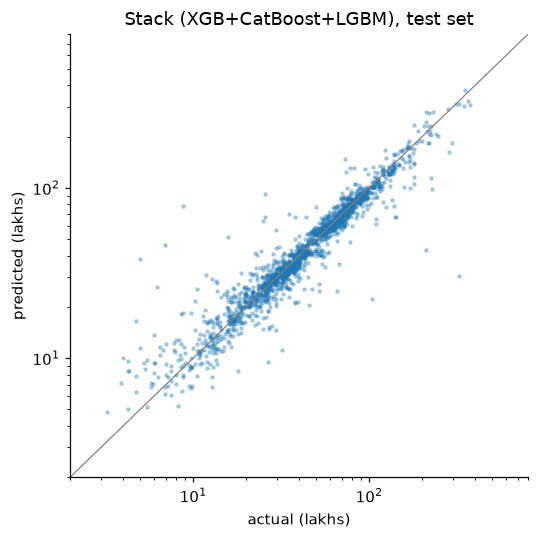

{'q10_log': -0.1555,
 'q90_log': 0.1685,
 'lower_pct': np.float64(-14.4),
 'upper_pct': np.float64(18.3),
 'test_coverage': 0.794}

In [21]:
resid = y_tr - oof[FINAL]      # out-of-fold residuals: errors on cars the model had not trained on
Q_LO, Q_HI = [float(x) for x in np.quantile(resid, [0.10, 0.90])]
final_te = test_pred[FINAL]
lo, hi = np.exp(final_te + Q_LO), np.exp(final_te + Q_HI)
coverage = float(np.mean((np.exp(y_te) >= lo) & (np.exp(y_te) <= hi)))
metrics["interval"] = {"q10_log": round(Q_LO, 4), "q90_log": round(Q_HI, 4),
                       "lower_pct": round((np.exp(Q_LO) - 1) * 100, 1), "upper_pct": round((np.exp(Q_HI) - 1) * 100, 1),
                       "test_coverage": round(coverage, 3)}
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(np.exp(y_te), np.exp(final_te), s=4, alpha=.3); lim = [2, 800]
ax.plot(lim, lim, color="grey", lw=.8); ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim,
        xlabel="actual (lakhs)", ylabel="predicted (lakhs)", title=f"{FINAL}, test set")
plt.tight_layout(); plt.savefig(FIG / "pred_vs_actual.png"); plt.show()
metrics["interval"]

### 6.5 What the output means

* **Age is by far the biggest driver.** Shuffling it raises MAPE by about 47 points. A 0–5-year-old car is about **+76 %** above the average listing, 11–15 years about +26 %, and 21–30 years about **−23 %**. In log terms the age effect is close to a straight line: roughly 4–5 % lower asking price per extra year from about 5 to 45 years, which is constant-percentage depreciation. Beyond about 45 years it turns upward, a classic-car premium based on few listings. Errors are higher for cars over 20 years old (§6.3), plausibly because condition, which the data does not record, varies most there.
* **Brand comes next** (+18 MAPE points when shuffled), then **gear** (+7.7), **engine size** (+7.0) and **model** (+6.8). Brand matters more than model because most models are rare. The model learns brand-level price tiers and uses `model` to refine them where data allow.
* **Automatic vs manual:** about **+9 %** vs **−12 %**, holding everything else equal. In Sri Lanka, automatics are newer Japanese imports and manuals are often older or Indian-built cars.
* **Hybrids carry no premium once model and age are known** (SHAP ≈ 0 %), even though their raw median price is almost twice petrol's (73.8 vs 38.5 lakhs). The raw gap is **confounding**: hybrids are recent models such as the Aqua, Vezel and Prius. A naive analysis would credit the fuel type. The model credits age and model instead.
* **An ongoing lease lowers the asking price by about 9 %.** A plausible reading is that the buyer must settle or take over the outstanding loan, so the seller discounts. This is an association, not a measured cause.
* **Town and equipment** (power mirror, window, steering, A/C) add little once make, model and age are known: under 1 point of MAPE each.
* **Where to trust it:** for popular cars (models seen 20+ times in training), the typical error is **4.3 %**. For a model the training data never contained, it is **14.3 %**, which is still far better than any lookup can do. The hardest cases are the cheapest quartile (11.6 %) and cars over 20 years old (10.8 %), where condition varies most and the data cannot see it. By brand, Suzuki (3.8 %) and Toyota (5.9 %) are priced well. Mazda (18.5 %) and Mitsubishi (15.8 %) are not: they have few listings spread across many different models.
* **The 80 % range is −14 % to +18 %** around the prediction. It is asymmetric because errors are symmetric in log space. Test coverage of 79.4 % shows it is calibrated overall. It is the same width for every car, though, so it is too wide for a common Alto and too narrow for a rare Mazda (§8).

## 7 · Export the model and run inference on the held-out car

The final model is saved with `joblib` to `model/price_model.joblib`, together with its 80 % interval and test metrics. Every class it needs is defined in `vehicle_model.py`, so the app can load it without the notebook. The file is a pickle, and loading a pickle can run code, so **load only a model you trained yourself**.

In [22]:
test_row = test_table.loc[FINAL]
final = PriceModel(fitted[FINAL], FINAL, (Q_LO, Q_HI),
                   metrics={"test_mape": float(test_row["MAPE %"]), "test_mdape": float(test_row["MdAPE %"]),
                            "test_r2": float(test_row["R² (price)"]), "interval_coverage": coverage})
final.save("model/price_model.joblib")
# Listings the app uses for dropdowns and "similar cars": training rows only, so nothing from the test set leaks into the app
data.iloc[tr][INPUT_COLUMNS + ["price", "date"]].to_csv("model/listings.csv", index=False)

reloaded = PriceModel.load("model/price_model.joblib")
assert np.allclose(reloaded.predict_log(X_te), final_te), "exported model must reproduce the test predictions"
print("model/:", sorted(p.name for p in Path("model").iterdir()))

model/: ['all_models.joblib', 'listings.csv', 'price_model.joblib']


**Every compared model, for the app's model picker.** Each model gets its own 80 % range from its *own* out-of-fold residuals, and its own typical error by how familiar the car's model is. The final stack is still the default; the others let a user see how much the choice of model moves the estimate.

In [23]:
familiar = seg["model seen in train"].values
all_models = {}
for n in TECHNIQUE:
    q_lo, q_hi = (float(q) for q in np.quantile(y_tr - oof[n], [0.10, 0.90]))
    p, t = test_pred[n], np.exp(y_te)
    s = scores(y_te, p)
    all_models[n] = PriceModel(fitted[n], n, (q_lo, q_hi), metrics={
        "technique": TECHNIQUE[n], "test_mape": s["MAPE %"], "test_mdape": s["MdAPE %"], "test_r2": s["R² (price)"],
        "interval_coverage": float(np.mean((t >= np.exp(p + q_lo)) & (t <= np.exp(p + q_hi)))),
        "mdape_by_familiarity": pd.Series(np.abs(np.exp(p) - t) / t * 100).groupby(familiar, observed=True).median().round(1).to_dict()})
joblib.dump(all_models, "model/all_models.joblib", compress=3)

reloaded_all = joblib.load("model/all_models.joblib")
for n, m in reloaded_all.items():
    assert np.allclose(m.predict_log(X_te), test_pred[n]), n
    e = explain(m.model, X_te.head(50))
    if e is not None:
        assert np.allclose(e[0] + e[1].sum(axis=1), m.predict_log(X_te.head(50)), atol=1e-4), n
print(f"model/all_models.joblib: {len(reloaded_all)} models, {Path('model/all_models.joblib').stat().st_size / 1e6:.1f} MB")

model/all_models.joblib: 9 models, 46.7 MB


In [24]:
x = add_features(inference_row)
pred = float(reloaded.predict(x)[0]); lo1, hi1 = (float(v[0]) for v in reloaded.interval(x))
actual = float(inference_row.price.iloc[0])
contrib = pd.Series(cb.get_feature_importance(Pool(x, cat_features=CAT_IDX), type="ShapValues")[0, :-1], index=FEATURES)
top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(6)
metrics["inference"] = {"car": inference_row[INPUT_COLUMNS].iloc[0].astype(str).to_dict(), "date": inference_row.date.iloc[0],
                        "actual_lakhs": actual, "predicted_lakhs": round(pred, 2), "range80": [round(lo1, 2), round(hi1, 2)],
                        "error_pct": round((pred - actual) / actual * 100, 1),
                        "catboost_top_contributions_pct": {k: round((np.exp(v) - 1) * 100, 1) for k, v in top.items()}}
print(f"Held-out car: {inference_row[['brand', 'model', 'yom', 'engine_cc', 'fuel', 'gear', 'town']].iloc[0].to_dict()}")
print(f"Asking price {actual:.2f} lakhs | predicted {pred:.2f} lakhs | 80 % range {lo1:.1f} – {hi1:.1f}")
print("Largest effects for this car vs the average car (CatBoost SHAP, %):", metrics["inference"]["catboost_top_contributions_pct"])

Held-out car: {'brand': 'TOYOTA', 'model': 'AQUA', 'yom': 2012, 'engine_cc': 1460.0, 'fuel': 'Hybrid', 'gear': 'Automatic', 'town': 'Boralesgamuwa'}
Asking price 70.95 lakhs | predicted 65.68 lakhs | 80 % range 56.2 – 77.7
Largest effects for this car vs the average car (CatBoost SHAP, %): {'age': np.float64(23.6), 'brand': np.float64(21.0), 'gear': np.float64(5.8), 'power_mirror': np.float64(4.0), 'engine_cc': np.float64(-2.7), 'model': np.float64(-1.7)}


**The same car, explained by the final stack.** The waterfall starts at the average log price and adds each feature's SHAP value until it reaches this car's prediction. The app shows this chart for any car a user enters.

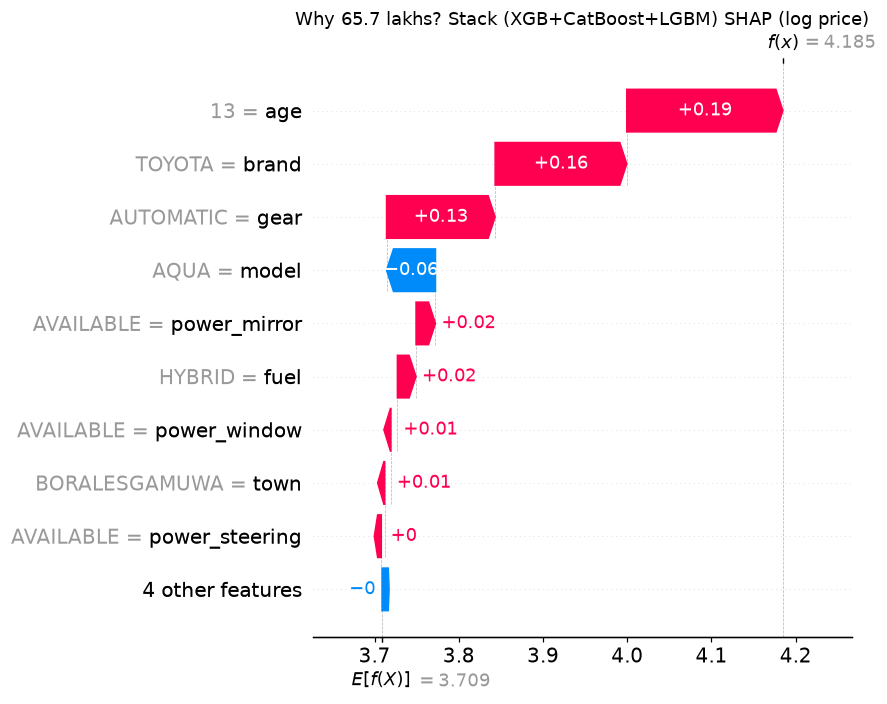

Largest effects for this car vs the average car (stack SHAP, %): {'age': np.float64(20.4), 'brand': np.float64(16.9), 'gear': np.float64(13.8), 'model': np.float64(-5.6), 'power_mirror': np.float64(2.3), 'fuel': np.float64(2.2)}


In [25]:
b1, s1 = explain(reloaded.model, x)
assert np.isclose(b1 + s1.values.sum(), reloaded.predict_log(x)[0], atol=1e-4)
ex1 = shap.Explanation(s1.values[0], base_values=b1, data=x.iloc[0].astype(str).values, feature_names=FEATURES)
shap.plots.waterfall(ex1, max_display=10, show=False)
plt.title(f"Why {pred:.1f} lakhs? {FINAL} SHAP (log price)"); plt.tight_layout()
plt.savefig(FIG / "shap_waterfall_inference.png", bbox_inches="tight"); plt.show()
top1 = s1.iloc[0].reindex(s1.iloc[0].abs().sort_values(ascending=False).index).head(6)
metrics["inference"]["stack_top_contributions_pct"] = {k: round((np.exp(v) - 1) * 100, 1) for k, v in top1.items()}
print("Largest effects for this car vs the average car (stack SHAP, %):", metrics["inference"]["stack_top_contributions_pct"])

In [26]:
(RES / "metrics.json").write_text(json.dumps(metrics, indent=1, default=str))
print("results/metrics.json written")

results/metrics.json written


## 8 · Limitations and conclusion

**Limitations**
1. **Asking prices, not sale prices.** Listings show what sellers hope to get. Negotiated prices are typically lower, and the data cannot measure by how much.
2. **No usable mileage or condition.** Mileage is synthetic (11,000 km × age), and there is no accident history, service record or bodywork condition. These are exactly the factors that explain the errors on old and cheap cars. Real odometer readings would be the single most valuable addition.
3. **A snapshot of a closed market.** The data was collected Dec 2024 – Feb 2025, at the end of a five-year import ban. Once imports resumed, used-car prices could shift substantially. The model will drift and must be retrained on post-liberalisation listings before it is trusted for current prices.
4. **The long tail.** 916 models appear only once. Predictions for rare models rely on the brand and on the age curve.
5. **Electric vehicles** (69 rows) have made-up engine sizes and too few examples, so EV predictions are low-confidence.
6. **One interval width for every car.** The 80 % range comes from global residuals. Segment-specific or quantile-regression intervals would be narrower for common cars and wider for rare ones.
7. **Data rights.** The data is scraped from ikman.lk and Riyasewana.com. The Kaggle release is MIT-licensed, but the marketplaces' own terms were not checked, so the data is used here for coursework only.

**Future work:** a hybrid that uses the comparable-listings median when at least ~10 matching listings exist and the stack otherwise (§3 suggests this would combine the median's 2.5 % error on common cars with the stack's coverage of the tail); quantile models for segment-aware ranges; and retraining on 2025–26 listings to measure the effect of import liberalisation.

**Conclusion.** On a real Sri Lankan market dataset, a stack of XGBoost, CatBoost and LightGBM predicts used-car asking prices with **13.0 % mean** and **6.3 % median** error on cars it has never seen (R² 0.89). It beats the linear regression used in earlier Sri Lankan studies, the common Random Forest / XGBoost approaches, and the "look up similar listings" practice buyers use today. The analysis also showed that this widely used dataset's mileage column is synthetic, so models that "learned from mileage" on it were learning age twice. The front end (`app.py`) turns the model into a practical fair-price check for buyers and sellers.